# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
plans.head(5)

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().mean()*100)

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id        0.000
first_name     0.000
last_name      0.000
age            0.000
city          11.725
reg_date       0.000
plan           0.000
churn_date    88.350
dtype: float64


In [11]:
# cantidad de nulos para usage
print(usage.isna().sum())
print(usage.isna().mean()*100)

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id           0.000
user_id      0.000
type         0.000
date         0.125
duration    55.190
length      44.740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
- Las columnas de mayor relevancia en cuanto a la proporción de datos faltanes son: city, con un 11%; churn date, con un 88% de datos faltantes; duration, con un 55% de valores nulos, y, finalmente, length, con un 44%.
- Indica qué harías: ¿imputar, eliminar, ignorar?
- Para el caso de churn date y debido a la proporción de los valores nulos, no se considerará para el análisis. Para el caso de city, si no se puede imputar, tendremos que ignorar esta parte de la población, con la respectiva aclaración. Para duración y lenght, podemos revisar la información de media, mediana y desviación estándar, así como los IQRs y outliers y con estos cálculos, buscar imputarlos, pero hay una observación importante que remarcar: las llamadas registradas por user_id tienen un dato de duration, mientras que si se trata de un texto, lo que se mide es lenght. En una segunda validación de datos y utilizando una condicional, solo hay que asegurar que existan los datos correspondientes dependiendo de si se trata de una llamada o un texto.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# explorar columnas numéricas de users
print(users[["user_id", "age"]].describe())

            user_id          age
count   4000.000000  4000.000000
mean   11999.500000    33.739750
std     1154.844867   123.232257
min    10000.000000  -999.000000
25%    10999.750000    32.000000
50%    11999.500000    47.000000
75%    12999.250000    63.000000
max    13999.000000    79.000000


- La columna `user_id` comienza a partir del número 10000 para el conteo de sus usuarios, y termina con el número 13999.
- La columna `age` tiene valores no válidos, como el mínimo de edad que marca -999, haciendo que los cálculos para mean y std sean afectados por este número incorrecto.

In [13]:
# explorar columnas numéricas de usage
print(usage[["id", "user_id"]].describe())

                id       user_id
count  40000.00000  40000.000000
mean   20000.50000  12002.405975
std    11547.14972   1157.279564
min        1.00000  10000.000000
25%    10000.75000  10996.000000
50%    20000.50000  12013.000000
75%    30000.25000  13005.000000
max    40000.00000  13999.000000


- Las columnas `id` y `user_id`...Haz doble clic en este bloque y escribe qué ves.
- La columna id solo es un listado que va del 1 al 40000 para registrar a sus clientes, mientras que user_id sigue la misma lógica antes mencionada: el registro de clientes comienza el 10000 y termina en 13999. A diferencia de la información de user_id encontrada en la data de users, los cálculos de mean, std y los quartiles son diferentes, lo que me hace inferir que hay usuarios que no se encuentran en ambas bases de datos, adicional a que el dataset users tiene 4000 registros, mientras que usage tiene 40000.

In [14]:
# explorar columnas categóricas de users
print(users[['city', 'plan']].describe())


          city    plan
count     3531    4000
unique       7       2
top     Bogotá  Basico
freq       808    2595


- La columna `city`´, como antes se mencionó, tiene una cantidad importante de valores faltantes (cerca de un 12%).Se observa que hay 7 ciudades diferentes en el dataset, donde Bogotá es la que tiene mayor popularidad.
- La columna `plan` cuenta con datos completos, solamente con dos valores únicos (plan básico y plan premium), y el que más predomina es el básico.

In [15]:
# explorar columna categórica de usage
print(usage['type'].describe())

count     40000
unique        2
top        text
freq      22092
Name: type, dtype: object


- La columna `type` nos hace saber que lo que más predomina entre llamadas y textos, es mensajes, con un poco más del 50% de participación total. Los registros en type también están completos.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?
- La columna de city tiene cerca de un 12% de valores faltantes, mientras que la columna de age tiene valores no válidos (-999).  
- ¿Qué acción tomarías?
- Revisaré cuantos son los datos incorrectos en la columna de edad(-999) para buscar reemplazarlos por la media o mediana. Para la columna de city, si no hay manera de inferir a que ciudad pertenecen los registros, lo que se tendría que ejecutar es no considerarlos, pero informar en el proyecto la razón por la cual no se considerarán dentro del análisis y que representan esos datos que se discriminarán.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:

# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors="coerce")


In [17]:
# Convertir a fecha la columna `date` de usage
usage['date'] =  pd.to_datetime(usage['date'], errors="coerce")

In [18]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].value_counts()

2026-05-10 00:00:00.000000000    40
2023-12-20 18:33:45.506376600     1
2022-11-21 17:58:06.571642912     1
2024-06-20 09:50:54.463615904     1
2022-05-22 00:23:45.956489122     1
                                 ..
2022-07-29 04:44:06.661665416     1
2022-02-22 00:36:43.750937734     1
2022-10-31 09:22:49.242310580     1
2022-09-24 16:46:48.702175544     1
2022-03-28 12:38:20.975243811     1
Name: reg_date, Length: 3961, dtype: int64

En `reg_date`, ... haz doble clic en este bloque y escribe qué ves.

De un total de 4000 registros en reg_date, tenemos 40 datos registrados con fecha del 2026 (1%). Podemos discriminarlos.

In [19]:
# Revisar los años presentes en `date` de usage
usage['date'].value_counts()

2024-06-16 13:26:59.770494262    1
2024-06-21 22:28:11.862296556    1
2024-06-06 11:09:26.204155102    1
2024-04-14 16:05:21.848046200    1
2024-04-01 14:39:43.079576989    1
                                ..
2024-04-13 22:49:17.653941348    1
2024-03-06 03:52:44.749118728    1
2024-03-21 23:20:13.140328508    1
2024-01-07 00:52:33.678841971    1
2024-04-08 01:44:47.917197929    1
Name: date, Length: 39950, dtype: int64

En `date`, ... haz doble clic en este bloque y escribe qué ves.  
Basaremos el análisis en estas fechas.

Para la columna date del dataset usage, tenemos una mayor cantidad de registros, pero las fechas corresponden a años válidos, mientras que el % de datos faltantes es discriminable.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- Si, en el dataset de users, tenemos 40 registros correspondientes a Mayo 2026.
- ¿Qué harías con ellas?
- Esos 40 registros representan el 1% del dataset de users, entonces haremos drop de esas fechas inválidas.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [20]:
# Reemplazar -999 por la mediana de age
age_mediana = print("La mediana es", users['age'].median())
print("La cantidad de datos sentinel es de:" , users['age'].isin([-999]).sum())
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

La mediana es 47.0
La cantidad de datos sentinel es de: 55


count    4000.000000
mean       48.143750
std        17.799868
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [21]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace("?", np.nan)

# Verificar cambios
users['city'].describe()

count       3435
unique         6
top       Bogotá
freq         808
Name: city, dtype: object

In [22]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year >= 2026, 'reg_date'] = np.nan

# Verificar cambios
users['reg_date'].describe()

count                              3960
unique                             3960
top       2024-06-27 06:08:22.325581392
freq                                  1
first               2022-01-01 00:00:00
last                2024-12-31 00:00:00
Name: reg_date, dtype: object

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [23]:
# Verificación MAR en usage (Missing At Random) para duration

print(usage['duration'].isna().groupby(usage['type']).value_counts())
usage['duration'].isna().groupby(usage['type']).mean()*100


type  duration
call  False       17908
text  True        22076
      False          16
Name: duration, dtype: int64


type
call     0.000000
text    99.927576
Name: duration, dtype: float64

In [24]:
# Verificación MAR en usage (Missing At Random) para length
print(usage['length'].isna().groupby(usage['type']).value_counts())
usage['length'].isna().groupby(usage['type']).mean()*100

type  length
call  True      17896
      False        12
text  False     22092
Name: length, dtype: int64


type
call    99.932991
text     0.000000
Name: length, dtype: float64

Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`
Se verificaron los valores faltantes de length, los cuales solo son aplicables para el caso de que se trate de un texto, y hay una proporción menor al .1% de valores no válidos. Lo mismo ocurre para el caso de duration, que es una cualidad que solo debe aplicar a las llamadas y que, sin embargo, se observan 16 registros en este campo que están bajo el tipo texto. 
Como ambos valores inválidos representan un porcentaje mínimo que no llega al .1%, considero que se puedan anular.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [25]:


# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas
usage["total_min_call"] = np.where(usage["type"] == "call", usage["duration"], 0)

print(usage["is_text"].sum())
print(usage["is_call"].sum())
print(usage["total_min_call"].sum())


# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg({"is_text": sum,"is_call": sum,"total_min_call": sum} ).reset_index()

# observar resultado
usage_agg.head(5)


22092
17908
91324.9


,user_id,is_text,is_call,total_min_call
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74
3,10003,11,3,8.99
4,10004,4,3,8.01


In [26]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={"is_text":"cant_mensajes", "is_call":"cant_llamadas","total_min_call":"cant_minutos_llamada"})

# observar resultado
usage_agg.head(5)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74
3,10003,11,3,8.99
4,10004,4,3,8.01


In [27]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = usage_agg.merge(users,on="user_id", how="left")
user_profile.head(5)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,7,3,23.70,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,5,10,33.18,Mateo,Torres,53,NaN,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,5,2,10.74,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,11,3,8.99,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,4,3,8.01,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [28]:
# Resumen estadístico de las columnas numéricas
user_profile[["cant_mensajes", "cant_llamadas", "cant_minutos_llamada", "age"]].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada,age
count,3999.000000,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,22.836934,48.146037
std,2.358416,2.144238,16.590213,17.801506
min,0.000000,0.000000,0.000000,18.000000
25%,4.000000,3.000000,11.095000,33.000000
50%,5.000000,4.000000,19.740000,48.000000
75%,7.000000,6.000000,31.185000,63.000000
max,17.000000,15.000000,155.690000,79.000000


In [29]:
# Distribución porcentual del tipo de plan
user_profile[["plan"]].value_counts(normalize=True)*100

plan   
Basico     64.866217
Premium    35.133783
dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

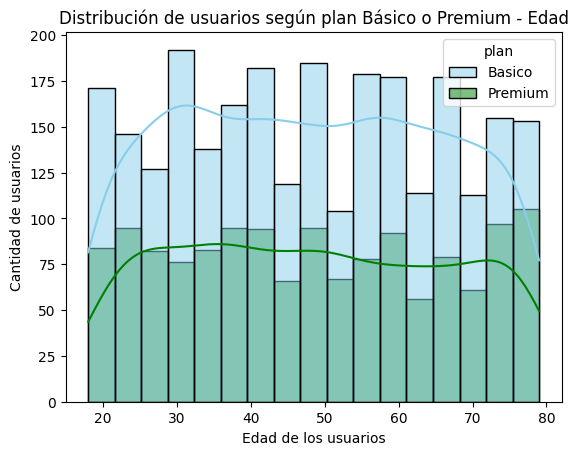

In [30]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x="age", hue="plan", palette=["skyblue","green"], kde=True)
plt.xlabel("Edad de los usuarios")
plt.ylabel("Cantidad de usuarios")
plt.title("Distribución de usuarios según plan Básico o Premium - Edad")
plt.show()

💡Insights: 
- Distribución:
  Para el plan Premium, observamos que es más popular entre los adultos mayores (rango de edad de 70 a 80 años), pero en general tiene un comportamiento uniforme en todos los rangos de edad.
  El plan Básico, por otra parte, es más popular entre los adultos jovenes (30 a 40 años), y los adultos maduros (50 a 65 años).

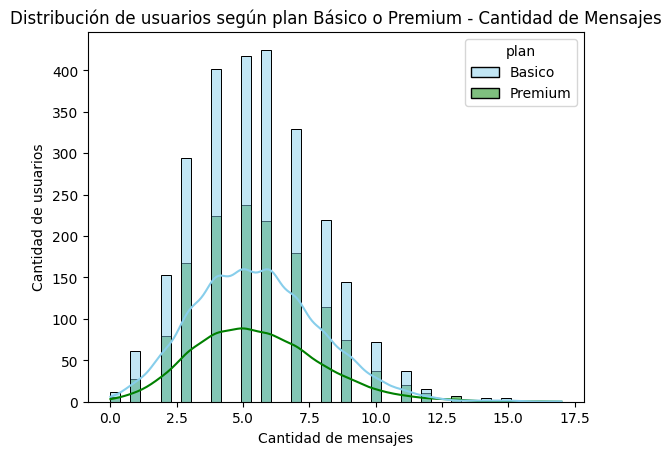

In [31]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x="cant_mensajes", hue="plan", palette=["skyblue","green"], kde=True)
plt.xlabel("Cantidad de mensajes")
plt.ylabel("Cantidad de usuarios")
plt.title("Distribución de usuarios según plan Básico o Premium - Cantidad de Mensajes")
plt.show()

💡Insights: 
- Vemos que la distribución está centrada, y la cantidad de mensajes que en general más envían los usuarios, tanto en plan premium como básico, es la misma: entre 2 y 8 mensajes (principalmente en plan premium). Para el plan básico, la cantidad de usuarios que utilizan los mensajes es aún mayor, pero los números son los mismos: de 2 a 8 mensajes. Podemos inferir, observando esta gráfica y la pasada, que los adultos mayores con Plan Premium no son usuarios populares de texto, mientras que los adultos jóvenes y maduros, en plan básico, si lo son.

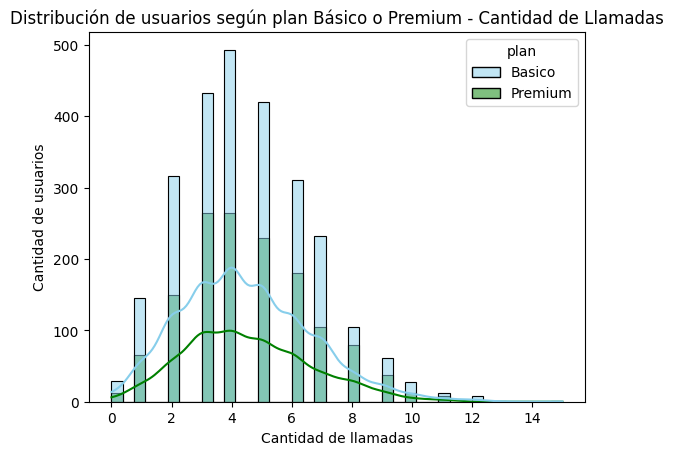

In [32]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x="cant_llamadas", hue="plan", palette=["skyblue","green"], kde=True)
plt.xlabel("Cantidad de llamadas")
plt.ylabel("Cantidad de usuarios")
plt.title("Distribución de usuarios según plan Básico o Premium - Cantidad de Llamadas")
plt.show()

💡Insights: 
- La distribución de la cantidad de llamadas tiene un ligero sesgo a la derecha, pero observamos que sigue un comportamiento muy similar a la cantidad de textos enviados, donde, en promedio, se realizan de entre 2 a 8 llamadas, pero es más grande la cantidad de usuarios dentro del plan básico que realizan llamadas. Dentro del plan premium, la cantidad de usuarios que eligen una llamada es menor.

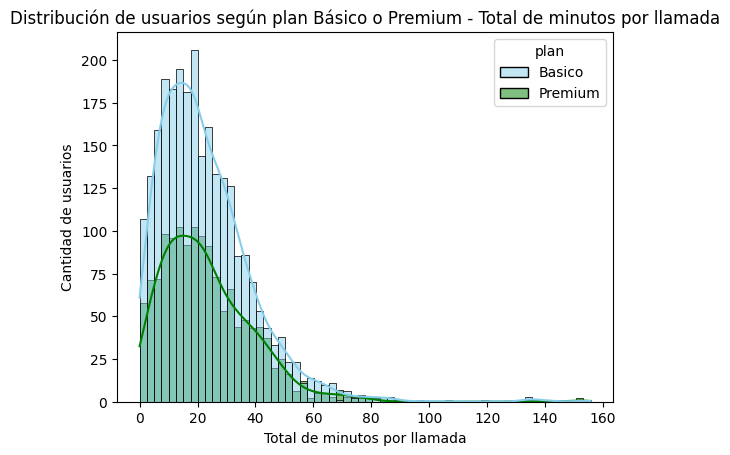

In [33]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x="cant_minutos_llamada", hue="plan", palette=["skyblue","green"], kde=True)
plt.xlabel("Total de minutos por llamada")
plt.ylabel("Cantidad de usuarios")
plt.title("Distribución de usuarios según plan Básico o Premium - Total de minutos por llamada")
plt.show()

💡Insights: 
- Encontramos que la distribución en esta gráfica está sesgada a la derecha, posiblemente por algunos outliers encontrados en el dataset. A grandes números, observamos que las llamadas en promedio duran 20 minutos, y van desde los 2 minutos hasta los 60 minutos; es aquí donde se concentra la mayor cantidad de minutos por llamada y de usuarios, tanto en plan básico, como en premium.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

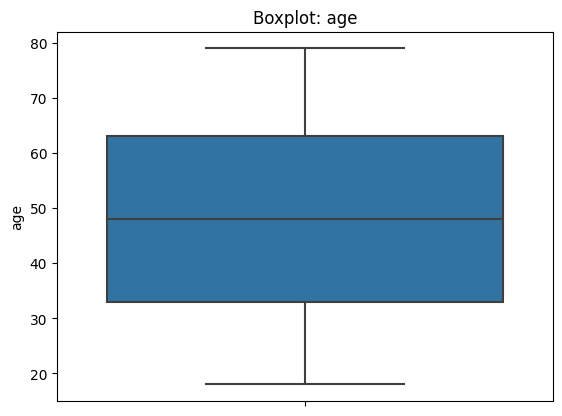

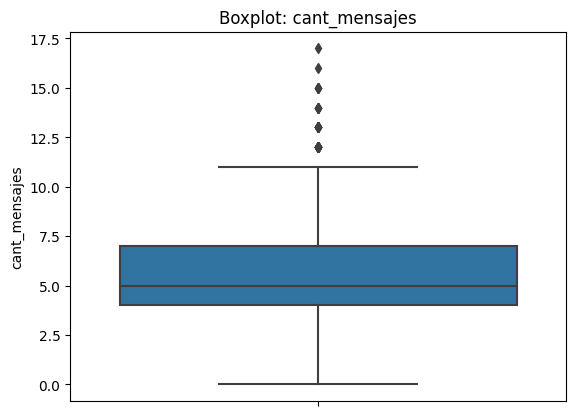

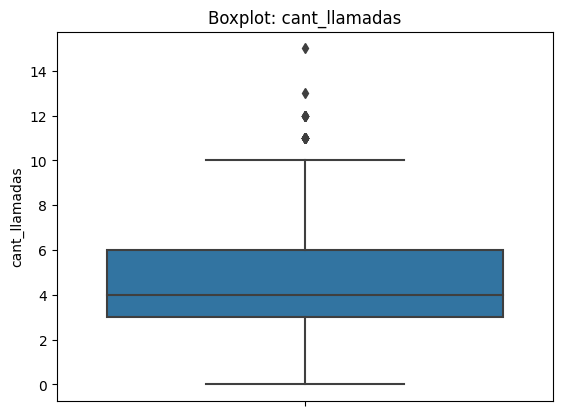

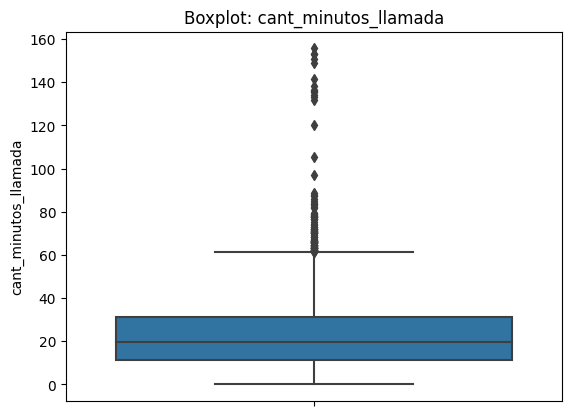

In [34]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure()
    sns.boxplot(y=user_profile[col])
    plt.title(f'Boxplot: {col}')
    plt.show()

💡Insights: 
- Age: no presenta outliers porque los valores inválidos (sentinels) fueron reemplazados a inicios del código.
- Cant_mensajes: Si presenta outliers.
- Cant_llamadas: También presenta unos cuantos outliers.
- Cant_minutos_llamada: cómo lo habíamos visto en el histograma, este parámetro presenta sesgo y en el boxplot podemos ver que hay valores muy por arriba que van desde los 60 hasta loas 160  minutos.
- Para todos las variables que presentan outliers, solo se ven en la parte superior; no hay en la parte inferior.

In [35]:
# Calcular límites con el método IQR
columnas_limites = ["cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]
for col in columnas_limites:
        Q1 = user_profile[col].quantile(0.25)
        print("Primer Quartil:", [col], Q1)
        Q3 = user_profile[col].quantile(0.75)
        print("Tercer Quartil:", [col], Q3)
        IQR = Q3 - Q1
        print("IQR:", [col], IQR)
        lower_limit = Q1 - 1.5 * IQR
        print("Límite inferior:", [col], lower_limit)
        upper_limit = Q3 + 1.5 * IQR
        print("Límite superior:", [col], upper_limit)

Primer Quartil: ['cant_mensajes'] 4.0
Tercer Quartil: ['cant_mensajes'] 7.0
IQR: ['cant_mensajes'] 3.0
Límite inferior: ['cant_mensajes'] -0.5
Límite superior: ['cant_mensajes'] 11.5
Primer Quartil: ['cant_llamadas'] 3.0
Tercer Quartil: ['cant_llamadas'] 6.0
IQR: ['cant_llamadas'] 3.0
Límite inferior: ['cant_llamadas'] -1.5
Límite superior: ['cant_llamadas'] 10.5
Primer Quartil: ['cant_minutos_llamada'] 11.094999999999999
Tercer Quartil: ['cant_minutos_llamada'] 31.185
IQR: ['cant_minutos_llamada'] 20.09
Límite inferior: ['cant_minutos_llamada'] -19.04
Límite superior: ['cant_minutos_llamada'] 61.31999999999999


In [36]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,22.836934
std,2.358416,2.144238,16.590213
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.095000
50%,5.000000,4.000000,19.740000
75%,7.000000,6.000000,31.185000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué? Podríamos discriminarlos, porque los outliers no son demasiados.
- cant_llamadas: mantener o no outliers, porqué? Si, es importante revisar los outliers de la cantidad de llamadas para verificar si son datos reales y, de ser así, que tipo de clientes son los que hacen más llamadas.
- cant_minutos_llamada: mantener o no outliers, porqué? De igual manera que en cant_llamadas, hay varios outliers que conviene revisar para verificar primero que son datos reales y que no es ningún error en captura de datos, y en segundo lugar, para revisar si hay una relación en cuanto a los mismos clientes que tienen más minutos por llamada y más llamadas realizadas, ya que podrían ser posibles clientes frecuentes.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [37]:
# Crear columna grupo_uso
def grupo_uso(fila):
    llamadas = fila["cant_llamadas"]
    mensajes = fila["cant_mensajes"]
    
    if llamadas < 5 and mensajes < 5:
        return "Bajo uso"
    elif llamadas < 10 and mensajes < 10:
        return "Uso medio"
    else:
        return "Alto uso"
        
user_profile['grupo_uso'] = user_profile.apply(grupo_uso, axis=1)

In [38]:
# verificar cambios
user_profile.head()

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,first_name,last_name,age,city,reg_date,plan,churn_date,grupo_uso
0,10000,7,3,23.70,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,Uso medio
1,10001,5,10,33.18,Mateo,Torres,53,NaN,2022-01-01 06:34:17.914478619,Basico,NaN,Alto uso
2,10002,5,2,10.74,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,Uso medio
3,10003,11,3,8.99,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,Alto uso
4,10004,4,3,8.01,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [39]:
# Crear columna grupo_edad
def grupo_edad(fila):
    edad = fila["age"]
        
    if edad < 30:
        return "Joven"
    elif edad < 60:
        return "Adulto"
    else:
        return "Adulto Mayor"
        
user_profile['grupo_edad'] = user_profile.apply(grupo_edad, axis=1)

In [40]:
# verificar cambios
user_profile.head()

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,first_name,last_name,age,city,reg_date,plan,churn_date,grupo_uso,grupo_edad
0,10000,7,3,23.70,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,Uso medio,Adulto
1,10001,5,10,33.18,Mateo,Torres,53,NaN,2022-01-01 06:34:17.914478619,Basico,NaN,Alto uso,Adulto
2,10002,5,2,10.74,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,Uso medio,Adulto
3,10003,11,3,8.99,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,Alto uso,Adulto Mayor
4,10004,4,3,8.01,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

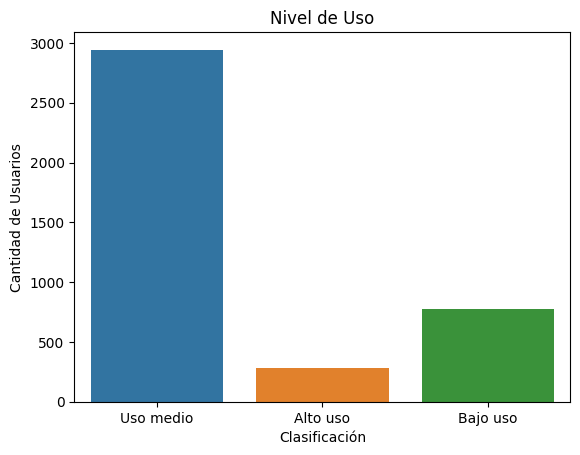

In [41]:
# Visualización de los segmentos por uso

sns.countplot(data=user_profile, x="grupo_uso")
plt.ylabel("Cantidad de Usuarios")
plt.xlabel("Clasificación")
plt.title("Nivel de Uso")
plt.show()


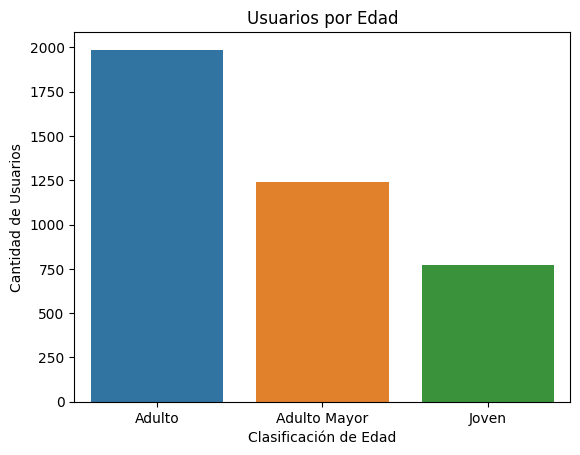

In [42]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x="grupo_edad")
plt.ylabel("Cantidad de Usuarios")
plt.xlabel("Clasificación de Edad")
plt.title("Usuarios por Edad")
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
**Valores nulos**  
- Las columnas de mayor relevancia en cuanto a la proporción de datos faltanes son: city, con un 11%; churn date, con un 88% de datos faltantes; duration, con un 55% de valores nulos, y, finalmente, length, con un 44%. Para el caso de churn date y debido a la proporción de los valores nulos, no se considerará para el análisis. Para el caso de city, no se pudo imputar así que se considero aplicar "NA" a las ciudades faltantes. Para duración y lenght, se observó que había valores menores al .1% que estaban incorrectos; es decir, duración solo aplica para el caso de llamadas, pero algunos registros de texto contaban con este valor, y viceversa; lenght solo aplica para el caso de texto, pero había registros de llamadas con información en este campo. Para el caso de age, se encontraron sentinels (999), mismos que fueron sustituidos por la mediana, y para el caso de date, se encontraron fechas en el futuro (registros de 2026), con la consideración de que el dataset abarca hasta 2024. También se invalidaron estos datos.

🔍 **Segmentos por Edad**
- Al final del proyecto, se marcaron tres clasificaciones por edad:
- Joven < 30 años
- Adulto < 60 años
- Adulto Mayor - el resto de la población.

📊 **Segmentos por Nivel de Uso**
- Respecto al nivel de uso, los usuarios fueron clasificados de acuerdo a la cantidad de llamadas y mensajes enviados con base en la siguiente escala:
- 'Bajo uso' cuando llamadas < 5 y mensajes < 5
- 'Uso medio' cuando llamadas < 10 y mensajes < 10
- 'Alto uso' para el resto de casos.

➡️ Esto sugiere que ...

Se encontraron las siguientes observaciones haciendo el análisis de uso en mensajes, textos y duración de las llamadas:
- Para el plan Premium, observamos que es más popular entre los adultos mayores (rango de edad de 70 a 80 años), pero en general tiene un comportamiento uniforme en todos los rangos de edad. El plan Básico, por otra parte, es más popular entre los adultos jovenes (30 a 40 años), y los adultos maduros (50 a 65 años).
- La cantidad de mensajes que en general más envían los usuarios, tanto en plan premium como básico, es la misma: entre 2 y 8 mensajes (principalmente en plan premium). Para el plan básico, la cantidad de usuarios que utilizan los mensajes es aún mayor, pero los números son los mismos: de 2 a 8 mensajes. Podemos inferir que los adultos mayores con Plan Premium no son usuarios populares de texto, mientras que los adultos jóvenes y maduros, en plan básico, si lo son. Observamos también que las llamadas en promedio duran 20 minutos, y van desde los 2 minutos hasta los 60 minutos; es aquí donde se concentra la mayor cantidad de minutos por llamada y de usuarios, tanto en plan básico, como en premium.

💡 **Recomendaciones**
- Con las observaciones antes mencionadas y con los outliers encontrados, específicamente hablando de la cantidad de llamadas y los minutos que estás pueden durar, mi recomendación es revisar los outliers con la finalidad de saber si con datos reales, o es un registro erróneao en cuanto a cantidad y duración de los outliers, y también con la intención de encontrar a posibles clientes que puedan hacer upgrade a plan Premium si es que solo cuentan con el plan básico, o incluso poder ofrecer alguna otra promoción para asegurar el engagement o premiar la fidelidad de aquellos clientes que tienen un uso más frecuente de los servicios.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`